In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
import numpy as np
from pygraphon.graphons import StepGraphon
from pygraphon.estimators import SmoothNetHist

from utils_generators import AssociativeFullyRandom
from pygraphon.norm import MseProbaEdge, MaeProbaEdge, AUCEdge, AUPRCEdge
import matplotlib.pyplot as plt
from pygraphon.plots.plot_matrices import spy


# Initialisation

In [5]:
n = 100
k = 2
theta_intra_min, theta_intra_max = 0.5, 0.7
theta_inter_min, theta_inter_max = 0.05, 0.2
theta = AssociativeFullyRandom(
                    K=k,
                    min_inside_classes=theta_intra_min,
                    max_inside_classes=theta_intra_max,
                    min_outside_classes=theta_inter_min,
                    max_outside_classes=theta_inter_max,
                )
print(theta.Theta)
graphon = StepGraphon(theta.Theta, bandwidthHist=1 / k)
adjacency_matrix = graphon.draw(n=n, exchangeable=False)

[[0.59636044 0.11118812]
 [0.11118812 0.50930929]]


# Olhede fit

In [6]:
est = SmoothNetHist()
first_hist_olhede = est._first_approximate_graphon_from_adjacency(adjacencyMatrix= adjacency_matrix)

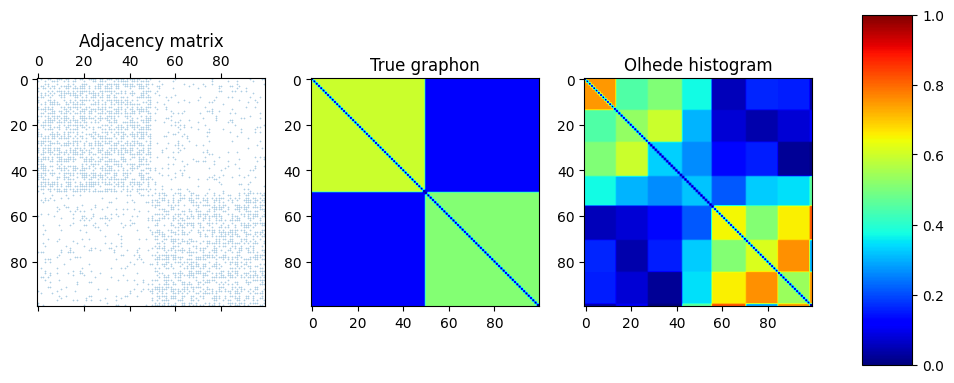

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im2 = ax[2].imshow(first_hist_olhede[0].get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
_ = spy(adjacency_matrix, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("True graphon")
ax[2].set_title("Olhede histogram")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)
plt.show()

Edge density:  0.49714285714285716
Edge density:  0.6
Edge density:  0.1110204081632653


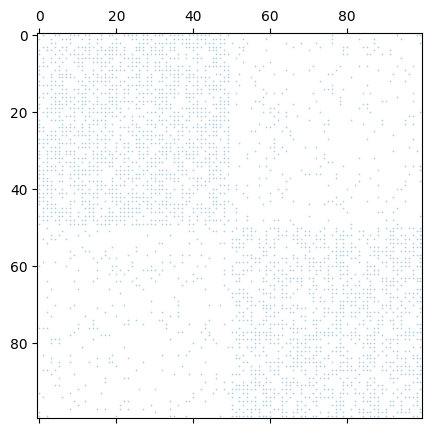

In [8]:
from pygraphon.utils import edge_density
spy(adjacency_matrix)
print("Edge density: ", edge_density(adjacency_matrix[int(n/2):, int(n/2):]))
print("Edge density: ", edge_density(adjacency_matrix[:int(n/2), :int(n/2)]))
print("Edge density: ", edge_density(adjacency_matrix[:int(n/2), int(n/2):]))

# Smooth NetHist fit 

In [9]:
my_est = SmoothNetHist()
my_est.fit(adjacency_matrix)

In [10]:
my_est._first_fit_graphon

In [11]:
print("Ratio of parameters:", my_est.get_ratio_par())
print("Number of unique parameters in SmoothNetHist:", len(np.unique(my_est.graphon.get_graphon())))
print("Number of unique parameters in Olhede:", len(np.unique(first_hist_olhede[0].get_graphon())))


Ratio of parameters: 0.2222222222222222
Number of unique parameters in SmoothNetHist: 8
Number of unique parameters in Olhede: 33


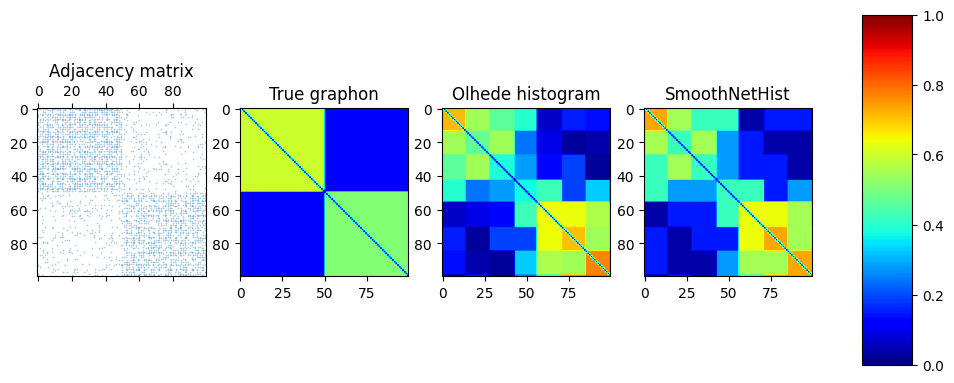

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im2 = ax[2].imshow(my_est._first_fit_graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im3 = ax[3].imshow(my_est.graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
_ = spy(adjacency_matrix, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("True graphon")
ax[2].set_title("Olhede histogram")
ax[3].set_title("SmoothNetHist")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)
plt.colorbar(im3, cax=cbar_ax)
plt.show()

In [13]:
my_est._first_fit_graphon

In [14]:
norm_olhede_mse = MseProbaEdge(n_nodes=n)(graphon, my_est._first_fit_graphon)
norm_olhede_mae = MaeProbaEdge(n_nodes=n)(graphon, my_est._first_fit_graphon)
norm_olhede_auc = AUCEdge(n_nodes=n)(adjacency_matrix, my_est._first_fit_graphon.get_edge_probabilities(n,False,True))
norm_olhede_auprc = AUPRCEdge(n_nodes=n)(adjacency_matrix, my_est._first_fit_graphon.get_edge_probabilities(n,False,True))

norm_smoothnet_mse = MseProbaEdge(n_nodes=n)(graphon, my_est.graphon)
norm_smoothnet_mae = MaeProbaEdge(n_nodes=n)(graphon, my_est.graphon)
norm_smoothnet_auc = AUCEdge(n_nodes=n)(adjacency_matrix, my_est.graphon.get_edge_probabilities(n,False,True))
norm_smoothnet_auprc = AUPRCEdge(n_nodes=n)(adjacency_matrix, my_est.graphon.get_edge_probabilities(n,False,True))

print("MSE Olhede vs SmoothNetHist:", norm_olhede_mse, norm_smoothnet_mse)
print("MAE Olhede vs SmoothNetHist:", norm_olhede_mae, norm_smoothnet_mae)
print("AUC Olhede vs SmoothNetHist:", norm_olhede_auc, norm_smoothnet_auc)
print("AUPRC Olhede vs SmoothNetHist:", norm_olhede_auprc, norm_smoothnet_auprc)

MSE Olhede vs SmoothNetHist: 0.02145336040750272 0.021880814132023363
MAE Olhede vs SmoothNetHist: 0.11523484820830034 0.1166712086512434
AUC Olhede vs SmoothNetHist: 0.7258456415152612 0.7246759497110479
AUPRC Olhede vs SmoothNetHist: 0.497680571767312 0.48869427821414707


# SmoothNetHist step by step

In [15]:
new_est = SmoothNetHist()
finite_est = new_est._approximate_graphon_from_adjacency(adjacencyMatrix= adjacency_matrix, number_link_communities= int((k+1)*k/2))


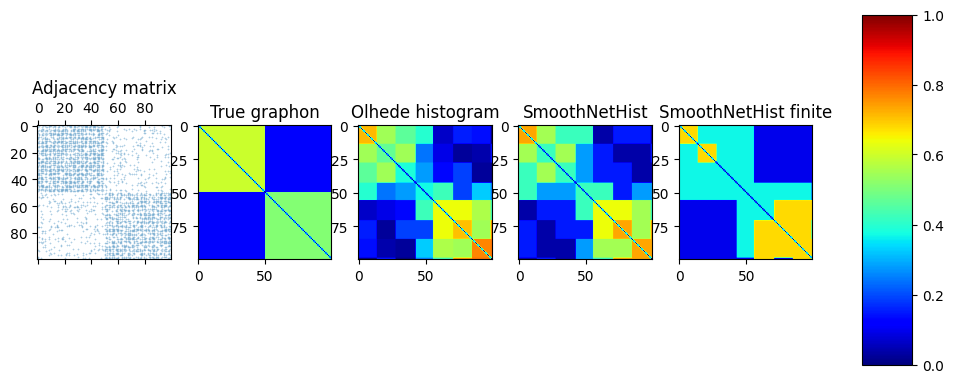

In [16]:
fig, ax = plt.subplots(1, 5, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im2 = ax[2].imshow(my_est._first_fit_graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im3 = ax[3].imshow(my_est.graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im4 = ax[4].imshow(finite_est[0].get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
_ = spy(adjacency_matrix, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("True graphon")
ax[2].set_title("Olhede histogram")
ax[3].set_title("SmoothNetHist")
ax[4].set_title("SmoothNetHist finite")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)
plt.colorbar(im3, cax=cbar_ax)
plt.colorbar(im4, cax=cbar_ax)
plt.show()

In [17]:
norm_smoothnet_mse_true = MseProbaEdge(n_nodes=n)(graphon, finite_est[0])
norm_smoothnet_mae_true = MaeProbaEdge(n_nodes=n)(graphon, finite_est[0])
norm_smoothnet_auc_true = AUCEdge(n_nodes=n)(adjacency_matrix, finite_est[0].get_edge_probabilities(n,False,True))
norm_smoothnet_auprc_true = AUPRCEdge(n_nodes=n)(adjacency_matrix, finite_est[0].get_edge_probabilities(n,False,True))

print("MSE Olhede vs SmoothNetHist vs Corrected:", norm_olhede_mse, norm_smoothnet_mse, norm_smoothnet_mse_true)
print("MAE Olhede vs SmoothNetHist vs Corrected:", norm_olhede_mae, norm_smoothnet_mae, norm_smoothnet_mae_true)
print("AUC Olhede vs SmoothNetHist vs Corrected:", norm_olhede_auc, norm_smoothnet_auc, norm_smoothnet_auc_true)
print("AUPRC Olhede vs SmoothNetHist vs Corrected:", norm_olhede_auprc, norm_smoothnet_auprc, norm_smoothnet_auprc_true)

MSE Olhede vs SmoothNetHist vs Corrected: 0.02145336040750272 0.021880814132023363 0.026293254748995003
MAE Olhede vs SmoothNetHist vs Corrected: 0.11523484820830034 0.1166712086512434 0.1292670057786277
AUC Olhede vs SmoothNetHist vs Corrected: 0.7258456415152612 0.7246759497110479 0.7013790929932826
AUPRC Olhede vs SmoothNetHist vs Corrected: 0.497680571767312 0.48869427821414707 0.45961194451938725


# Other plots for paper

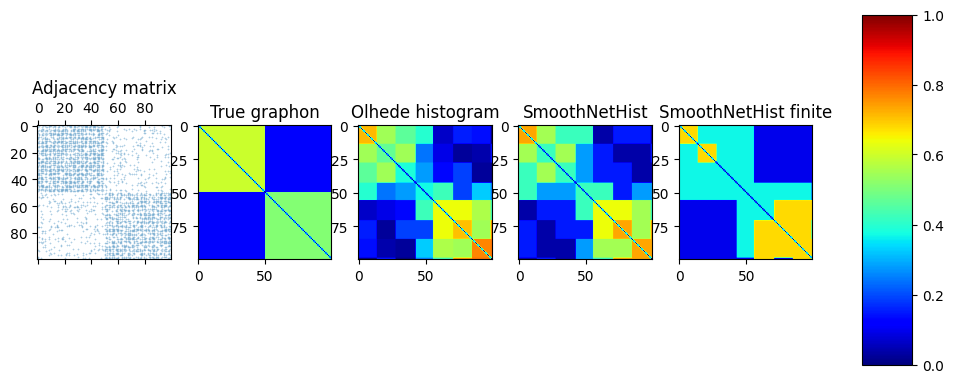

In [18]:
fig, ax = plt.subplots(1, 5, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im2 = ax[2].imshow(my_est._first_fit_graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im3 = ax[3].imshow(my_est.graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im4 = ax[4].imshow(finite_est[0].get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
_ = spy(adjacency_matrix, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("True graphon")
ax[2].set_title("Olhede histogram")
ax[3].set_title("SmoothNetHist")
ax[4].set_title("SmoothNetHist finite")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)
plt.colorbar(im3, cax=cbar_ax)
plt.colorbar(im4, cax=cbar_ax)
plt.show()

# Polblog

In [30]:
import io
from zipfile import ZipFile
import requests
import pandas as pd
import networkx as nx

url =  "https://networks.skewed.de/net/polblogs/files/polblogs.csv.zip"
response = requests.get(url, stream=True)
with ZipFile(io.BytesIO(response.content)) as myzip:
   with myzip.open(myzip.namelist()[0]) as myfile:
      df = pd.read_csv(myfile)
   with myzip.open(myzip.namelist()[1]) as myfile:
      df2 = pd.read_csv(myfile)

df.columns = ["source", "target"]
df2.columns = [s.replace(" ","") for s in df2.columns]
z = df2["value"].values
#df2.columns = ["value"] # 0 for liberals, 1 for conservative
A = nx.to_numpy_array(nx.from_pandas_edgelist(df, "source", "target"))
# we remove the diagonal to avoid self-loops
A -= np.diag(np.diag(A))

In [38]:
df2.columns = [s.replace(" ","") for s in df2.columns]

array([0, 0, 0, ..., 1, 1, 1], dtype=int64)

(<Figure size 500x500 with 1 Axes>, <AxesSubplot:>)

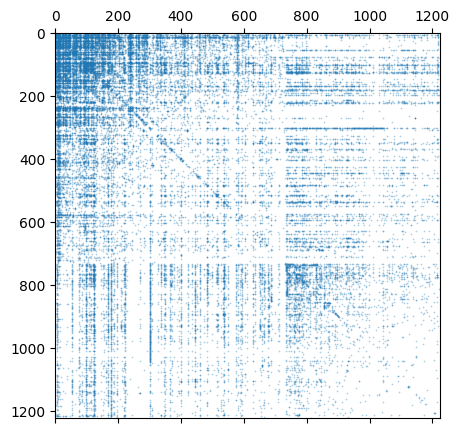

In [21]:
spy(A)

In [ ]:
est = SmoothNetHist()
first_hist_olhede = est._first_approximate_graphon_from_adjacency(adjacencyMatrix= adjacency_matrix)

In [25]:
with ZipFile(io.BytesIO(response.content)) as myzip:
   print(myzip.namelist())
   with myzip.open(myzip.namelist()[1]) as myfile:
      df2 = pd.read_csv(myfile)


['edges.csv', 'nodes.csv', 'gprops.csv']


In [26]:
df2

,# index,label,source,value,_pos
0,0,100monkeystyping.com,Blogarama,0,"array([ 19.03671634, -10.42473 ])"
1,1,12thharmonic.com/wordpress,BlogCatalog,0,"array([ 18.10776658, -11.24572572])"
2,2,40ozblog.blogspot.com,"Blogarama,BlogCatalog",0,"array([69.56083707, 8.50116954])"
3,3,4lina.tblog.com,Blogarama,0,"array([ 71.3610143, -36.0253674])"
4,4,750volts.blogspot.com,Blogarama,0,"array([12.55226328, -4.49266626])"
...,...,...,...,...,...
1485,1485,youngconservative.blogspot.com,Blogarama,1,"array([21.80678212, 4.98447147])"
1486,1486,zebrax.blogs.com,BlogCatalog,1,"array([22.18782507, -0.88783548])"
1487,1487,zeke01.blogspot.com,"Blogarama,BlogCatalog",1,"array([27.18837511, 6.18937681])"
1488,1488,zeke01.typepad.com,Blogarama,1,"array([22.52547573, 1.00735071])"
